In [1]:
import pandas as pd
import seaborn as sns

In [5]:
from sklearn import linear_model as lm
lr = lm.LinearRegression()
lr

LinearRegression()

In [6]:
df_small = pd.read_csv('Rounded_Student_Hours_Studied_vs_Marks_Dataset.csv')
df_small

,Hours_Studied,Marks
0,4.76,46.27
1,3.00,34.30
2,2.08,33.63
3,4.04,47.81
4,9.49,66.26
...,...,...
95,3.20,28.66
96,9.76,70.27
97,4.54,43.99
98,9.03,65.17


In [8]:
cor = df_small.corr()
cor

,Hours_Studied,Marks
Hours_Studied,1.000000,0.948974
Marks,0.948974,1.000000


In [12]:
x = df_small[['Hours_Studied']]
y = df_small['Marks']

lr.fit(x,y)

LinearRegression()

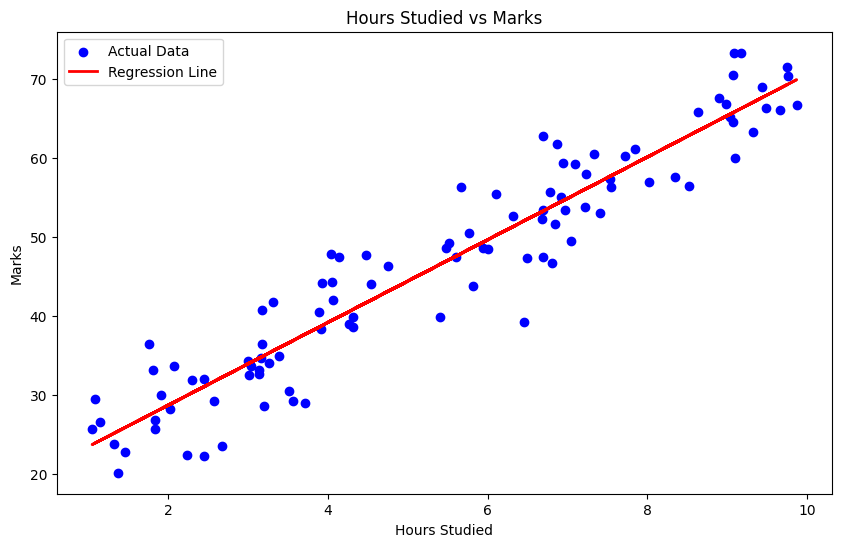

In [14]:
import matplotlib.pyplot as plt

# Generate predictions for the line
y_pred = lr.predict(x)

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='blue', label='Actual Data') # Scatter plot
plt.plot(x, y_pred, color='red', linewidth=2, label='Regression Line') # Line
plt.title('Hours Studied vs Marks')
plt.xlabel('Hours Studied')
plt.ylabel('Marks')
plt.legend()
plt.show()

In [15]:
from sklearn.metrics import r2_score, mean_squared_error

# Analysis Outputs
print(f"Coefficient (Slope): {lr.coef_[0]:.2f}")
print(f"Intercept: {lr.intercept_:.2f}")

# Performance Metrics
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"R-squared Score: {r2:.4f}")
print(f"Mean Squared Error: {mse:.2f}")

Coefficient (Slope): 5.23
Intercept: 18.25
R-squared Score: 0.9006
Mean Squared Error: 20.09


In [17]:
# predict for a new score
new_marks = lr.predict([[4.5]])
print(f"Predicted Marks for 4.5 hours of study: {new_marks[0]:.2f}")

Predicted Marks for 4.5 hours of study: 41.78


C:\Users\malli\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [23]:
df_med = pd.read_csv('Advertising.csv')
df_med = df_med.drop('Unnamed: 0', axis=1)
df_med

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


In [24]:
cor = df_med.corr()
cor

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


In [25]:
from sklearn.model_selection import train_test_split

x = df_med[['TV', 'Radio', 'Newspaper']]
y = df_med['Sales']

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [26]:
lr.fit(x_train, y_train)

LinearRegression()

In [33]:
y_pred = lr.predict(x_test)
y_train_pred = lr.predict(x_train)

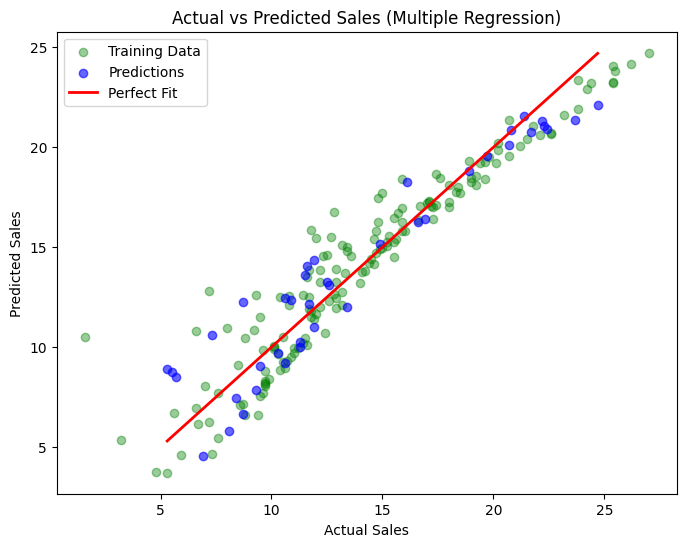

In [34]:
plt.figure(figsize=(8, 6))
# Plotting Actual Sales vs Predicted Sales
plt.scatter(y_train, y_train_pred, color='green', alpha=0.4, label='Training Data')
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Predictions')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Perfect Fit')

plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales (Multiple Regression)')
plt.legend()
plt.show()

In [39]:
# Analysis Outputs
print(f"Coefficient (Slope): {lr.coef_[0]:.2f}")
print(f"Intercept: {lr.intercept_:.2f}")

# Performance Metrics for train
r2 = r2_score(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)

print(f"R-squared Score (Train): {r2:.4f}")
print(f"Mean Squared Error (Train): {mse:.2f}")

# Performance Metrics
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"R-squared Score (Test): {r2:.4f}")
print(f"Mean Squared Error (Test): {mse:.2f}")

Coefficient (Slope): 0.04
Intercept: 2.98
R-squared Score (Train): 0.8957
Mean Squared Error (Train): 2.71
R-squared Score (Test): 0.8994
Mean Squared Error (Test): 3.17


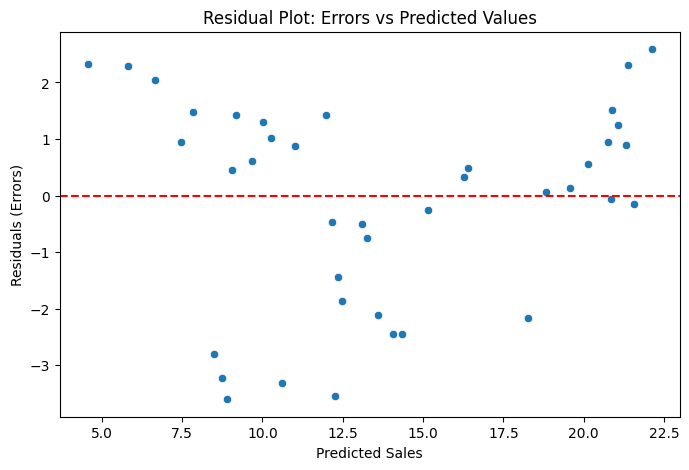

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

# IF ERRORS HAVE A PATTERN IT MEANS THAT THE MODEL ISNT GOOD
# Calculate residuals (Errors)
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residual Plot: Errors vs Predicted Values')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals (Errors)')
plt.show()

In [41]:
# Create an interaction term
df_med['TV_Radio_Combo'] = df_med['TV'] * df_med['Radio']

# Now try correlation again
print(df_med.corr()['Sales'].sort_values(ascending=False))

Sales             1.000000
TV_Radio_Combo    0.963932
TV                0.782224
Radio             0.576223
Newspaper         0.228299
Name: Sales, dtype: float64


In [12]:
import pandas as pd

df_big = pd.read_csv('housing.csv')
df_big

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [17]:
# 1. Remove rows with null values (total_bedrooms has 207 missing values)
df_big = df_big.dropna(subset=['total_bedrooms'])

# 2. Multiply Total Bedrooms and Households
df_big['bedroom_household_combo'] = df_big['total_bedrooms'] * df_big['households']

# 3. Verify there are no more nulls
print(f"Missing values after cleaning: {df_big.isnull().sum().sum()}")
print(f"New DataFrame shape: {df_big.shape}")

Missing values after cleaning: 0
New DataFrame shape: (20433, 16)


In [18]:
# This will return an array of all unique categories
print(df_big['ocean_proximity'].unique())

# If you want to see how many houses are in each category:
print(df_big['ocean_proximity'].value_counts())

['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']
ocean_proximity
<1H OCEAN     9034
INLAND        6496
NEAR OCEAN    2628
NEAR BAY      2270
ISLAND           5
Name: count, dtype: int64


In [19]:
# 1. Create dummy variables for all 5 categories
dummies = pd.get_dummies(df_big['ocean_proximity'], prefix='location', dtype=int)
df_big = pd.concat([df_big, dummies], axis=1)

# 4. Update your correlation to see how all 5 impact price
cor = df_big.corr(numeric_only=True)
print("\nCorrelation with Median House Value:")
print(cor['median_house_value'].sort_values(ascending=False))


Correlation with Median House Value:
median_house_value         1.000000
median_income              0.688355
location_<1H OCEAN         0.257614
location_<1H OCEAN         0.257614
location_NEAR BAY          0.160526
location_NEAR BAY          0.160526
location_NEAR OCEAN        0.140378
location_NEAR OCEAN        0.140378
total_rooms                0.133294
housing_median_age         0.106432
households                 0.064894
total_bedrooms             0.049686
bedroom_household_combo    0.034082
location_ISLAND            0.023525
location_ISLAND            0.023525
population                -0.025300
longitude                 -0.045398
latitude                  -0.144638
location_INLAND           -0.484787
location_INLAND           -0.484787
Name: median_house_value, dtype: float64


In [15]:
from sklearn import linear_model as lm
lr = lm.LinearRegression()
lr

LinearRegression()

In [21]:
from sklearn.model_selection import train_test_split

# Manual Selection for LR
x = df_big.drop(['median_house_value', 'ocean_proximity'], axis=1)
y = df_big['median_house_value']

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [25]:
lr.fit(x_train, y_train)

y_pred = lr.predict(x_test)

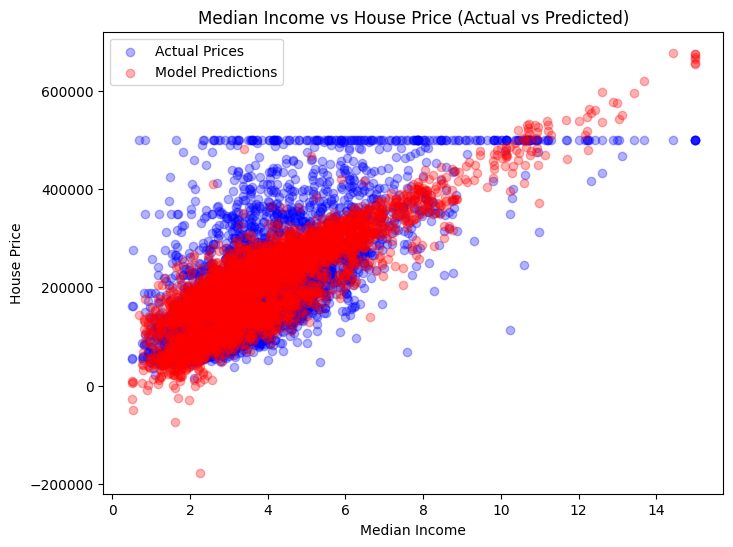

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
# Plotting Actual Sales vs Predicted Sales
plt.scatter(x_test['median_income'], y_test, color='blue', alpha=0.3, label='Actual Prices')
plt.scatter(x_test['median_income'], y_pred, color='red', alpha=0.3, label='Model Predictions')

plt.xlabel('Median Income')
plt.ylabel('House Price')
plt.title('Median Income vs House Price (Actual vs Predicted)')
plt.legend()
plt.show()